In [1]:
# Génération du sommaire à partir des titres markdown du notebook
import json, re

NB_PATH = r"c:\Users\John\Desktop\Projets_data\Porosimetre\Calcul_porosité_v5.ipynb"

with open(NB_PATH, encoding="utf-8") as f:
    nb = json.load(f)
lignes_sommaire = []
for cell in nb["cells"]:
    if cell["cell_type"] != "markdown":
        continue
    for line in "".join(cell["source"]).splitlines():
        m = re.match(r"(#+)\s+(.+)", line.strip())
        if not m:
            continue
        niveau, titre = len(m.group(1)), m.group(2).strip()
        ancre = titre.replace(" ", "-")          # convention : espaces -> tirets
        lignes_sommaire.append("  " * (niveau - 1) + f"- [{titre}](#{ancre})")

print("\n".join(lignes_sommaire))

- [Partie 1 : Détermination du point d'observation](#Partie-1-:-Détermination-du-point-d'observation)
  - [1-Récupération de l'image](#1-Récupération-de-l'image)
  - [2-Définition des points caractéristiques](#2-Définition-des-points-caractéristiques)
  - [3-Visualisation de l'image avec les points caractéristiques](#3-Visualisation-de-l'image-avec-les-points-caractéristiques)
  - [4-Modélisation du cylindre, du plan de projection et du point d'observation (calcul)](#4-Modélisation-du-cylindre,-du-plan-de-projection-et-du-point-d'observation-(calcul))
  - [5-Projection du cylindre sur le plan de projection (calcul)](#5-Projection-du-cylindre-sur-le-plan-de-projection-(calcul))
  - [6-Visualisation 3D (cylindre, point d'observation, projection)](#6-Visualisation-3D-(cylindre,-point-d'observation,-projection))
  - [7-Visualisation 2D (cylindre + point d'observation et projection)](#7-Visualisation-2D-(cylindre-+-point-d'observation-et-projection))
  - [8-Calcul de la projection des point

- [Partie 1 : Détermination du point d'observation](#Partie-1-:-Détermination-du-point-d'observation)
  - [1-Récupération de l'image](#1-Récupération-de-l'image)
  - [2-Définition des points caractéristiques](#2-Définition-des-points-caractéristiques)
  - [3-Visualisation de l'image avec les points caractéristiques](#3-Visualisation-de-l'image-avec-les-points-caractéristiques)
  - [4-Modélisation du cylindre, du plan de projection et du point d'observation (calcul)](#4-Modélisation-du-cylindre,-du-plan-de-projection-et-du-point-d'observation-(calcul))
  - [5-Projection du cylindre sur le plan de projection (calcul)](#5-Projection-du-cylindre-sur-le-plan-de-projection-(calcul))
  - [6-Visualisation 3D (cylindre, point d'observation, projection)](#6-Visualisation-3D-(cylindre,-point-d'observation,-projection))
  - [7-Visualisation 2D (cylindre + point d'observation et projection)](#7-Visualisation-2D-(cylindre-+-point-d'observation-et-projection))
  - [8-Calcul de la projection des points caractéristiques et visualisation](#8-Calcul-de-la-projection-des-points-caractéristiques-et-visualisation)
  - [9-Définition de la fonction de perte](#9-Définition-de-la-fonction-de-perte)
  - [10-Définition de l'espace des points d'observation](#10-Définition-de-l'espace-des-points-d'observation)
  - [11-Grille de visualisation 2D (cylindre et point d'observation)](#11-Grille-de-visualisation-2D-(cylindre-et-point-d'observation))
  - [12-Grille de visualisation 2D (projection + perte)](#12-Grille-de-visualisation-2D-(projection-+-perte))
  - [13-Visualisation d'une solution sur l'image de départ](#13-Visualisation-d'une-solution-sur-l'image-de-départ)
  - [14-Recherche par grille du meilleur point d'observation](#14-Recherche-par-grille-du-meilleur-point-d'observation)
- [Partie 2 : Détermination des dimensions d'une porosité](#Partie-2-:-Détermination-des-dimensions-d'une-porosité)

# Partie 1 : Détermination du point d'observation

In [2]:
# Import
import matplotlib.pyplot as plt
import numpy as np
from math import dist
from scipy.optimize import minimize
from scipy.spatial import procrustes
from sklearn.metrics import pairwise_distances
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from PIL import Image
from itertools import combinations


THETA = np.linspace(0, 2 * np.pi, 100) # pour tracer les cercles
LENGTH = 118 # Les variables LENGTH et RADIUS du cylindre
RADIUS = 48.5

## 1-Récupération de l'image

In [3]:
img = Image.open(r"c:\Users\John\Desktop\Projets_data\Porosimetre\data\97_118_5.png")
img = img.rotate(-90)

## 2-Définition des points caractéristiques

In [4]:
A = np.array([111, 50]) # les coordonnées sont trouvés en visualisant l'image en 3 - red
B = np.array([3, 194]) # blue
C = np.array([158,205]) # green
D = np.array([203, 126]) # yellow

## 3-Visualisation de l'image avec les points caractéristiques

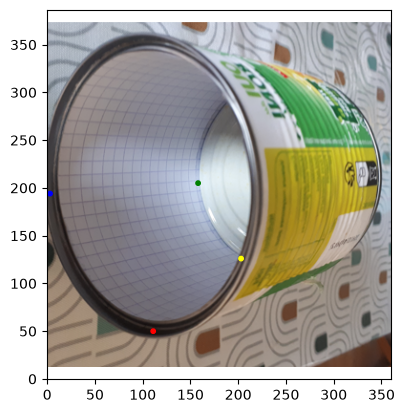

In [5]:
plt.imshow(img, origin='lower')
plt.scatter(np.array([A, B, C, D])[:, 0], np.array([A, B, C, D])[:, 1], s=10, c= ['red', 'blue', 'green', 'yellow'])
plt.show()

## 4-Modélisation du cylindre, du plan de projection et du point d'observation (calcul)

In [6]:
# Les cercles de base du cylindre
x_circle1, y_circle1, z_circle1 = RADIUS*np.cos(THETA),RADIUS*np.sin(THETA), np.full_like(THETA, LENGTH/2)
x_circle2, y_circle2, z_circle2 = RADIUS*np.cos(THETA), RADIUS*np.sin(THETA), np.full_like(THETA, -LENGTH/2)

# Le point de vue
# Initialisation du point de vue O
O = np.array([60, 0, 200])

# Le plan de projection 
# Il est défini par un point P0 et un vecteur normal n. On choisit arbitrairement
P0 = 0.8 * O
n = O
# Création d'une grille de points (xp, yp, zp)
xp = np.linspace(-2*RADIUS, 2*RADIUS, 20)
yp = np.linspace(-2*RADIUS, 2*RADIUS, 20)
Xp, Yp = np.meshgrid(xp, yp) # meshgrid est nécessaire pour plot_surface

# Résolution de l'équation du plan pour z : n_x*(x - P0_x) + n_y*(y - P0_y) + n_z*(z - P0_z) = 0
# => z = P0_z - (n_x*(x - P0_x) + n_y*(y - P0_y)) / n_z
Zp = P0[2] - (n[0]*(Xp - P0[0]) + n[1]*(Yp - P0[1])) / n[2]

## 5-Projection du cylindre sur le plan de projection (calcul)

In [7]:
# Fonction pour projeter un point P sur le plan défini par le point P0 et le vecteur normal A par rapport à un point de vue O
def projeter(P, n=O, P0=0.8*O, O=O):
    '''Projette un point P observé depuis le point d'observation O sur un plan de projection défini par son vecteur normal n et un point P0
    args :
        P (np.array(3)) : les coordonnées du point observé
    return :
        np.array(3) : les coordonnées de la projection du point P sur le plan de projection par homothétie de centre O (le point d'observation)
        '''
    # Vecteur OP
    OP = O - P
    # Intersection de OP avec le plan
    denom = np.dot(n, OP)
    if abs(denom) < 1e-12:
        # rayon parallèle au plan : pas d'intersection valide
        return 1e12   # grande valeur pénalisante, jamais NaN ni inf

    t = np.dot(n, P0 - P) / denom
    if not np.isfinite(t):
        return 1e12

    return P + t * OP

# Projection des deux cercles du cylindre sur le plan de projection
cyl_proj1 = np.array([projeter(np.array([x_circle1[i], y_circle1[i], z_circle1[i]])) for i in range(len(THETA))])
cyl_proj2 = np.array([projeter(np.array([x_circle2[i], y_circle2[i], z_circle2[i]])) for i in range(len(THETA))])

## 6-Visualisation 3D (cylindre, point d'observation, projection)

Text(0.5, 0.92, 'Projection du cylindre sur le plan de projection')

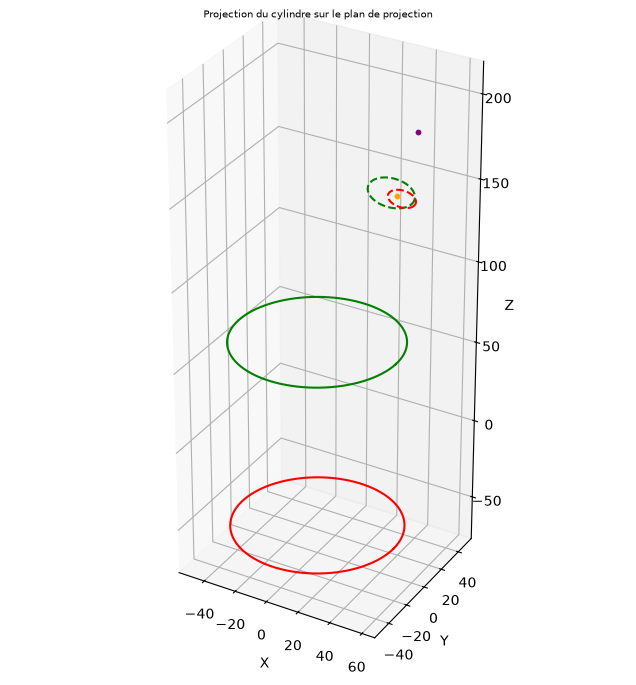

In [8]:
# Définition de la figure et des axes 3D
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Tracé des cercles de base du cylindre
ax.plot(x_circle1, y_circle1, z_circle1, color='green', label='Cercle1 de base du cylindre')
ax.plot(x_circle2, y_circle2, z_circle2, color='red', label='Cercle2 de base du cylindre')

# Tracé du point P0
ax.scatter(P0[0], P0[1], P0[2], color='orange', s=10, label='Point P0 (centre du plan de projection)')

# Tracé du plan de projection
#ax.plot_surface(Xp, Yp, Zp, alpha=0.5, color='lightblue', label='Plan')

# Tracé du point d'observation' O
ax.scatter(O[0], O[1], O[2], color='purple', s=10, label='Point d\'observation O')

# Tracé de la projection du cylindre sur le plan de projection
ax.plot(cyl_proj1[:, 0], cyl_proj1[:, 1], cyl_proj1[:, 2], color='green', linestyle='--', label='Projection du cercle1 sur le plan')
ax.plot(cyl_proj2[:, 0], cyl_proj2[:, 1], cyl_proj2[:, 2], color='red', linestyle='--', label='Projection du cercle2 sur le plan')

# Configuration du graphique
ax.set_aspect('equal')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Projection du cylindre sur le plan de projection', fontsize=7)

## 7-Visualisation 2D (cylindre + point d'observation et projection)

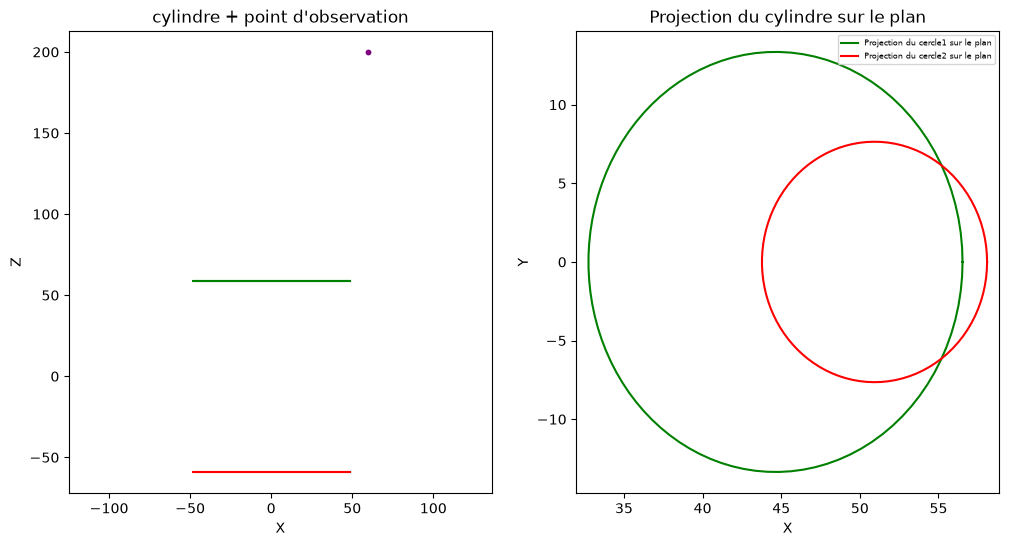

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Cylindre
# Tracé des cercles de base du cylindre
ax[0].plot(x_circle1, z_circle1, color='green', label='Cercle1 de base du cylindre')
ax[0].plot(x_circle2, z_circle2, color='red', label='Cercle2 de base du cylindre')

# Tracé du point d'observation O
ax[0].scatter(O[0], O[2], color='purple', s=10, label='Point d\'observation O')

# Configuration du graphique
ax[0].axis('equal')
ax[0].set_xlabel('X')
ax[0].set_ylabel('Z')
ax[0].set_title('cylindre + point d\'observation')

# Projection
# Tracé de la projection du cylindre 
ax[1].plot(cyl_proj1[:, 0], cyl_proj1[:, 1], color='green', label='Projection du cercle1 sur le plan')
ax[1].plot(cyl_proj2[:, 0], cyl_proj2[:, 1], color='red', label='Projection du cercle2 sur le plan')

# Configuration du graphique
ax[1].axis('equal')
ax[1].set_xlabel('X')
ax[1].set_ylabel('Y')
ax[1].set_title('Projection du cylindre sur le plan')
ax[1].legend(loc='upper right', fontsize='6')

## 8-Calcul de la projection des points caractéristiques et visualisation

In [10]:
# Calcul de Dp qui est le point d'intersection des deux cercles projetés
def intersection(nuage_1, nuage_2):
    '''intersection(nuage_1, nuage_2) donne les coordonnées du point du nuage de points nuage_1 le plus proche du nuage de points nuage_2
        args :
            nuage_1 (np.array(n x np.array(2))) : nuage de points 1
            nuage_2 (np.array(m x np.array(2))) : nuage de points 2
        return :
            Dp (np.array(2)) : point Dp
    '''
    dist_matrix = pairwise_distances(nuage_1, nuage_2, metric='euclidean')

    # Cas particulier où il n'y a pas de point d'intersection => il faut disqualifier ce cas
    if np.min(dist_matrix) > 10:
        return np.array([RADIUS, RADIUS]) # ?

    idx = np.where(dist_matrix==np.min(dist_matrix))

    # On choisit le point de du bas
    if cyl_proj1[idx[0][0]][1] < 0 :
        Dp = cyl_proj1[idx[0][0]]
        return Dp
    else :
        Dp = cyl_proj1[idx[0][0]]
        Dp[1] = -cyl_proj1[idx[0][0]][1]
        return Dp

# Calcul de la projection des points caractéristiques
Ap = cyl_proj1[np.argmin(cyl_proj1[:,1])][:2]
Bp = cyl_proj1[np.argmin(cyl_proj1[:,0])][:2]
Cp = cyl_proj2[np.argmin(cyl_proj2[:,0])][:2]
Dp = intersection(cyl_proj1, cyl_proj2)[:2] # car la fonction renvoie un point en 3D !

(np.float64(31.4800128709922),
 np.float64(59.3566612455902),
 np.float64(-14.688147246189832),
 np.float64(14.688147246189832))

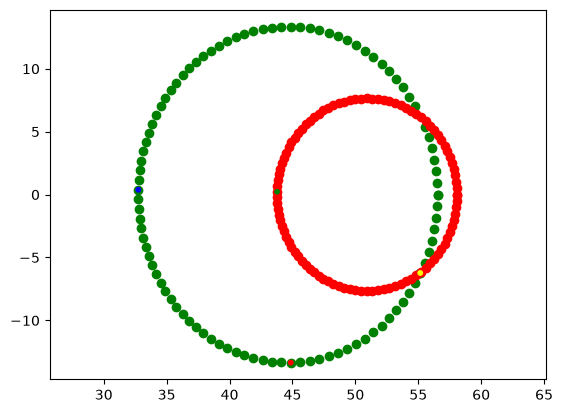

In [11]:
# Visualisons les cercles projetés et les points Ap, Bp, Cp, Dp
plt.scatter(cyl_proj1[:,0], cyl_proj1[:,1], c='green')
plt.scatter(cyl_proj2[:,0], cyl_proj2[:,1], c='red')
plt.scatter(np.array([Ap, Bp, Cp, Dp])[:, 0], np.array([Ap, Bp, Cp, Dp])[:, 1], s=10, c= ['red', 'blue', 'green', 'yellow'])
plt.axis('equal')

## 9-Définition de la fonction de perte

In [12]:
# C'est la SE des rapports de distances entre figure réelle et figure projetée
def loss_function(reel : list, proj : list)->int :
    liste_dist_reel = np.array([dist(P[0], P[1]) for P in combinations(reel, 2)])
    liste_prop_reel = np.array([dist[0]/dist[1] for dist in combinations(liste_dist_reel, 2)])

    liste_dist_proj = np.array([dist(P[0], P[1]) for P in combinations(proj, 2)])
    liste_prop_proj = np.array([dist[0]/dist[1] for dist in combinations(liste_dist_proj, 2)])

    return np.sum((liste_prop_reel - liste_prop_proj)**2)

# Exemple : 
loss_function(reel=[A, B, C, D], proj=[Ap, Bp, Cp, Dp])

np.float64(2.710225930148893)

## 10-Définition de l'espace des points d'observation

Text(0.5, 1.0, "cylindre + point d'observation")

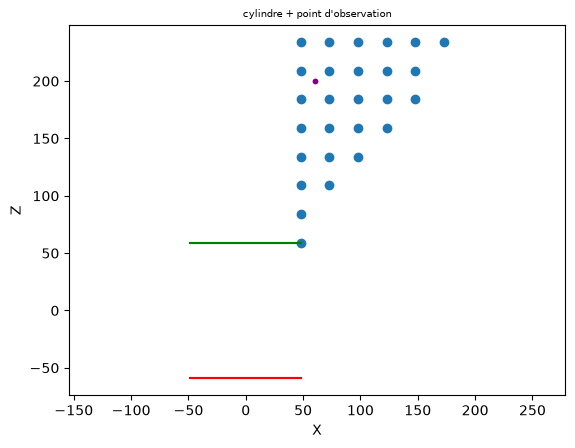

In [13]:
# Visualisation 2D
# Tracé des cercles de base du cylindre
plt.plot(x_circle1, z_circle1, color='green', label='Cercle1 de base du cylindre')
plt.plot(x_circle2, z_circle2, color='red', label='Cercle2 de base du cylindre')

# Tracé du point d'observation O
plt.scatter(O[0], O[2], color='purple', s=10, label='Point de vue O')

# Liste des candidats point d'observation candidats
X, Z = np.meshgrid(range(int(RADIUS), int(RADIUS) + 200, 25), range(int(0.5*LENGTH), int(0.5*LENGTH) + 200, 25)) 
a = LENGTH/(2*RADIUS) # voir 4 et 7
b = (LENGTH/2) - a*RADIUS # voir 4 et 7
mask = Z > a*X + b
plt.scatter(X[mask],Z[mask]) # Les points candidats

# Configuration du graphique
plt.axis('equal')
plt.xlabel('X')
plt.ylabel('Z')
plt.title('cylindre + point d\'observation', fontsize=7)


## 11-Grille de visualisation 2D (cylindre et point d'observation)

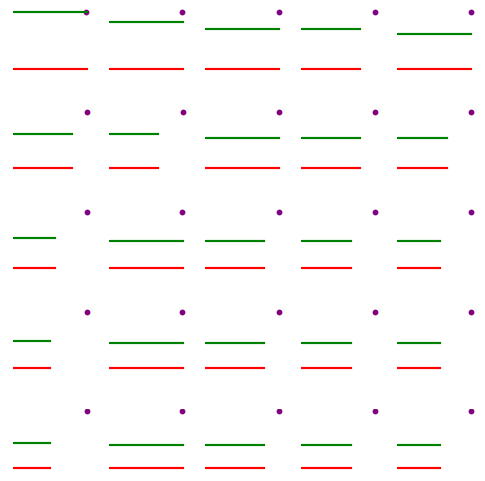

In [14]:
# Recherche de la solution par grille
fig, ax = plt.subplots(5, 5, figsize=(6,6))
fig.subplots_adjust(hspace=0.6)
ax = ax.flatten()
for i, p in enumerate(zip(X[mask][:25],Z[mask][:25])):
    # Tracé des cercles de base du cylindre
    ax[i].plot(x_circle1, z_circle1, color='green', label='Cercle1 de base du cylindre')
    ax[i].plot(x_circle2, z_circle2, color='red', label='Cercle2 de base du cylindre')

    # Tracé du point de vue O
    ax[i].scatter(p[0], p[1], color='purple', s=10, label='Point de vue O')
    #ax[i].set_title(f'{p}', fontsize=8)

    ax[i].axis('off')


## 12-Grille de visualisation 2D (projection + perte)

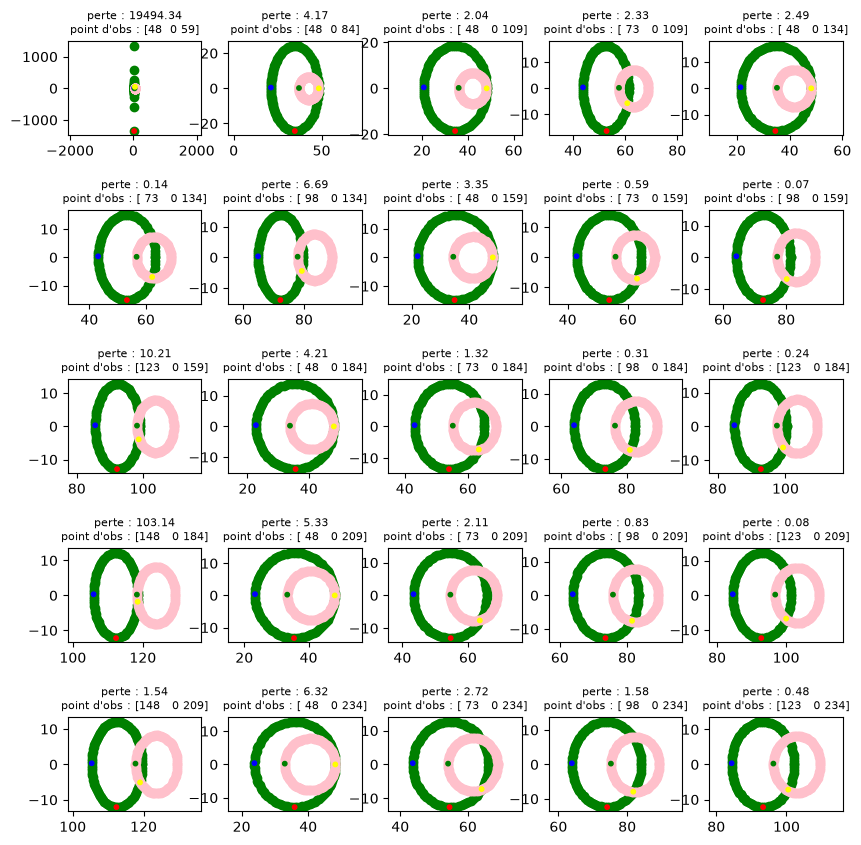

In [15]:
# On regarde plusieurs configurations avec leurs pertes
fig, ax = plt.subplots(5, 5, figsize=(10,10))
fig.subplots_adjust(hspace=0.8)
ax = ax.flatten()
# Visualisation d'une configuration et sa perte
 # Pour le point de vue donné O
for i in range(25):
    # Initialisation du point d'observation et du plan de projection
    O = np.array([X[mask][i], 0, Z[mask][i]])
    n = O # il faudrait figer ce paramètre dans la fonction
    P0 = 0.8*n # il faudrait figer ce paramètre dans la fonction

    # Projection des deux cercles du cylindre sur le plan de projection  
    cyl_proj1 = np.array([projeter(np.array([x_circle1[i], y_circle1[i], z_circle1[i]]), n=O, P0=0.8*O, O=O) for i in range(len(THETA))])
    cyl_proj2 = np.array([projeter(np.array([x_circle2[i], y_circle2[i],z_circle2[i]]), n=O, P0=0.8*O, O=O) for i in range(len(THETA))])

    # Déduction des points Ap, Bp, Cp, Dp
    Ap = cyl_proj1[np.argmin(cyl_proj1[:,1])][:2]
    Bp = cyl_proj1[np.argmin(cyl_proj1[:,0])][:2]
    Cp = cyl_proj2[np.argmin(cyl_proj2[:,0])][:2]
    Dp = intersection(cyl_proj1, cyl_proj2)[:2]

    # On visualise la projection et on édite la perte
    ax[i].scatter(cyl_proj1[:,0], cyl_proj1[:,1], c='green')
    ax[i].scatter(cyl_proj2[:,0], cyl_proj2[:,1], c='pink')
    ax[i].scatter(np.array([Ap, Bp, Cp, Dp])[:, 0], np.array([Ap, Bp, Cp, Dp])[:, 1], s=10, c= ['red', 'blue', 'green', 'yellow'])
    ax[i].axis('equal')
    loss = loss_function([A, B, C, D], [Ap, Bp, Cp, Dp])
    ax[i].set_title(f"perte : {loss:.2f}\npoint d'obs : {O}", fontsize=8)


## 13-Visualisation d'une solution sur l'image de départ

Text(0.5, 1.0, 'pt_d_obs : [ 88   0 159]\n loss : 0.0950621480082449')

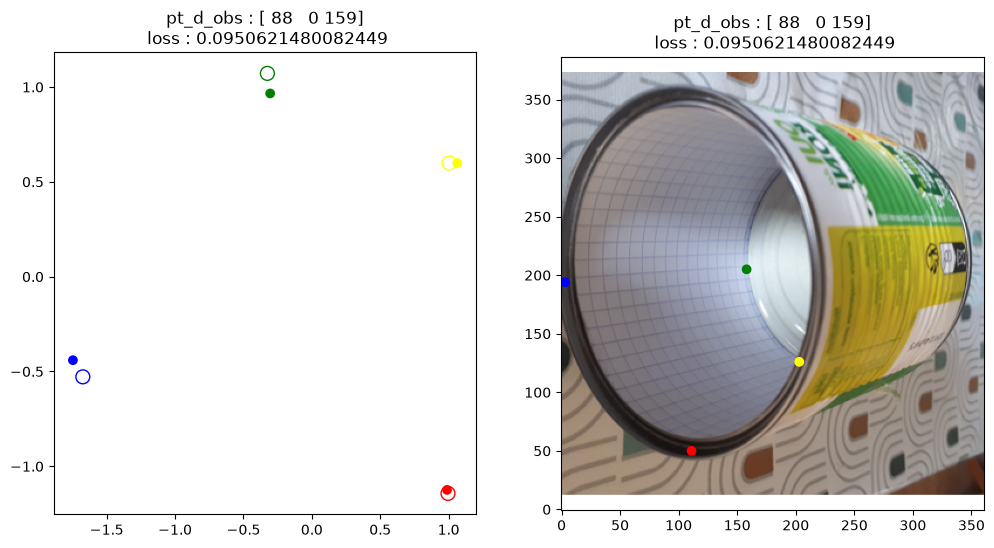

In [16]:
# Point d'observation
O = np.array([88, 0, 159]) # voir 11 et 12 (le meilleur étant celui qui minimise la perte [108, 0, 179])

# Définition du plan de projection
## Le plan de projection 
## Il est défini par un point P0 et un vecteur normal n. On choisit arbitrairement
P0 = 0.8 * O
n = O
## Création d'une grille de points (xp, yp, zp)
xp = np.linspace(-2*RADIUS, 2*RADIUS, 20)
yp = np.linspace(-2*RADIUS, 2*RADIUS, 20)
Xp, Yp = np.meshgrid(xp, yp) # meshgrid est nécessaire pour plot_surface

## Résolution de l'équation du plan pour z : n_x*(x - P0_x) + n_y*(y - P0_y) + n_z*(z - P0_z) = 0
## => z = P0_z - (n_x*(x - P0_x) + n_y*(y - P0_y)) / n_z
Zp = P0[2] - (n[0]*(Xp - P0[0]) + n[1]*(Yp - P0[1])) / n[2]

# Projection du cylindre sur le plan de projection
## Projection des deux cercles du cylindre sur le plan de projection
cyl_proj1 = np.array([projeter(np.array([x_circle1[i], y_circle1[i], z_circle1[i]]), n=O, P0=0.8*O, O=O) for i in range(len(THETA))])
cyl_proj2 = np.array([projeter(np.array([x_circle2[i], y_circle2[i], z_circle2[i]]), n=O, P0=0.8*O, O=O) for i in range(len(THETA))])

# Calcul des points caractéristiques Ap, Bp, Cp, Dp sur le plan de projection
## Calcul de la projection des points caractéristiques
Ap = cyl_proj1[np.argmin(cyl_proj1[:,1])][:2]
Bp = cyl_proj1[np.argmin(cyl_proj1[:,0])][:2]
Cp = cyl_proj2[np.argmin(cyl_proj2[:,0])][:2]
Dp = intersection(cyl_proj1, cyl_proj2)[:2] # car la fonction renvoie un point en 3D !

# Vérification de la similitude entre les deux figures (réelle et projetée) par pca 
# (attention : le scaling se fait selon chaque axe et pas sur l'ensemble des points)
scaler = StandardScaler().fit(np.array([A, B, C, D]))
scaler_p = StandardScaler().fit(np.array([Ap, Bp, Cp, Dp]))

x_scaled = scaler.transform(np.array([A, B, C, D]))
xp_scaled = scaler_p.transform(np.array([Ap, Bp, Cp, Dp]))

pca = PCA(n_components=2).fit(x_scaled)
pca_p = PCA(n_components=2).fit(xp_scaled)

X_reduced = pca.transform(x_scaled)
Xp_reduced = pca_p.transform(xp_scaled)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].scatter(Xp_reduced[:, 0], Xp_reduced[:, 1], c= ['red', 'blue', 'green', 'yellow'])
ax[0].scatter(-X_reduced[:, 0], X_reduced[:, 1], edgecolors=['red', 'blue', 'green', 'yellow'], facecolors='none', s=100) # Attention à l'inversion de l'axe X avec pca
ax[0].set_title(f'pt_d_obs : {O}\n loss : {loss_function([A, B, C, D], [Ap, Bp, Cp, Dp])}')

# Visualisation sur l'image
ax[1].imshow(img, origin='lower')
ax[1].scatter(np.array([A, B, C, D])[:, 0], np.array([A, B, C, D])[:, 1], c= ['red', 'blue', 'green', 'yellow'])
ax[1].set_title(f'pt_d_obs : {O}\n loss : {loss_function([A, B, C, D], [Ap, Bp, Cp, Dp])}')


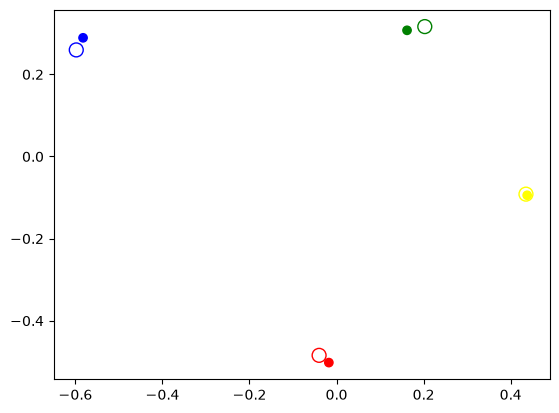

In [17]:
# Autre méthode de Procrustes pour vérifier la similitude entre les deux figures (réelle et projetée)
# Le scaling se fait sur l'ensemble des points et pas selon chaque axe ?

mtx1, mtx2, disparity = procrustes(np.array([A, B, C, D]),
                                   np.array([Ap, Bp, Cp, Dp]))
plt.scatter(mtx2[:, 0], mtx2[:, 1], c= ['red', 'blue', 'green', 'yellow'])
plt.scatter(mtx1[:, 0], mtx1[:, 1], edgecolors=['red', 'blue', 'green', 'yellow'], facecolors='none', s=100)

## 14-Recherche par grille du meilleur point d'observation

In [18]:
def optimizer(x : float, z : float):
    '''Cette fonction prend une abscisse x et une ordonnée z du point d'observation.
    Avec ce point dobservation la fonction de perte est calculée.
    Args :
        x (float) : l'abscisse du point d'observation
        z (float) : l'ordonnée du point d'observation
    Returns : 
        (float) : la perte
    '''

    # Définition du point d'observation
    O = np.array([x, 0, z])
    #print('z : ', z)
    # Définition du plan de projection
    ## Le plan de projection 
    ## Il est défini par un point P0 et un vecteur normal n. On choisit arbitrairement
    P0 = 0.8 * O
    n = O
    ## Création d'une grille de points (xp, yp, zp)
    xp = np.linspace(-2*RADIUS, 2*RADIUS, 20)
    yp = np.linspace(-2*RADIUS, 2*RADIUS, 20)
    Xp, Yp = np.meshgrid(xp, yp) # meshgrid est nécessaire pour plot_surface

    ## Résolution de l'équation du plan pour z : n_x*(x - P0_x) + n_y*(y - P0_y) + n_z*(z - P0_z) = 0
    ## => z = P0_z - (n_x*(x - P0_x) + n_y*(y - P0_y)) / n_z
    Zp = P0[2] - (n[0]*(Xp - P0[0]) + n[1]*(Yp - P0[1])) / n[2]
    
    # Projection du cylindre sur le plan de projection
    ## Projection des deux cercles du cylindre sur le plan de projection
    cyl_proj1 = np.array([projeter(np.array([x_circle1[i], y_circle1[i], z_circle1[i]]), n=O, P0=0.8*O, O=O) for i in range(len(THETA))])
    cyl_proj2 = np.array([projeter(np.array([x_circle2[i], y_circle2[i], z_circle2[i]]), n=O, P0=0.8*O, O=O) for i in range(len(THETA))])

    #cyl_proj2 = np.array([projeter(np.array([x_circle2[i], y_circle2[i], z_circle2[i]])) for i in range(len(THETA))])

    # Calcul des points caractéristiques Ap, Bp, Cp, Dp sur le plan de projection
    ## Calcul de la projection des points caractéristiques
    Ap = cyl_proj1[np.argmin(cyl_proj1[:,1])][:2]
    Bp = cyl_proj1[np.argmin(cyl_proj1[:,0])][:2]
    Cp = cyl_proj2[np.argmin(cyl_proj2[:,0])][:2]
    Dp = intersection(cyl_proj1, cyl_proj2)[:2] # car la fonction renvoie un point en 3D !
    # print('A, B, C, D :', [A, B, C, D])
    # print('Ap, Bp, Cp, Dp :', [Ap, Bp, Cp, Dp])
    # print(loss_function(reel=[A, B, C, D], proj=[Ap, Bp, Cp, Dp]))
    # calcule la loss_function
    return loss_function(reel=[A, B, C, D], proj=[Ap, Bp, Cp, Dp])


In [ ]:
# Recherche par grille
loss = 1000
for x, z in zip(X[mask],Z[mask]): 
    perte = optimizer(x, z)
    # calcul de la perte et du point d'observation
    if perte < loss:
        loss = perte # bug ?
        best_O = np.array([x, 0, z])
    else:
        continue
print(f'perte : {loss}\nmeilleur point d\'observation : {best_O}')

perte : 0.0729228270460991
meilleur point d'observation : [ 98   0 159]


Text(0.5, 1.0, 'pt_d_obs : [ 98   0 159]\n loss : 0.0729228270460991')

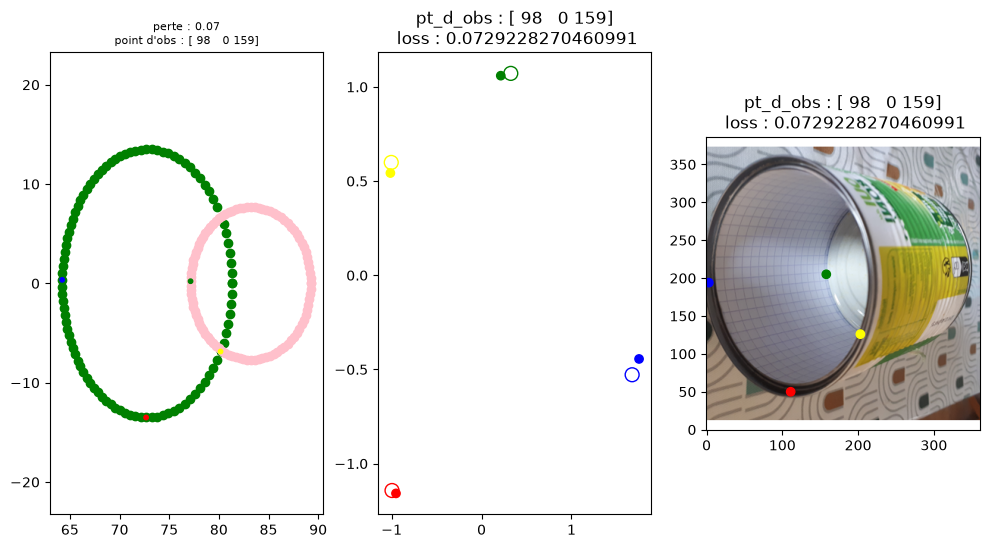

In [20]:
# Visualisation de la solution
O = best_O
n = O # il faudrait figer ce paramètre dans la fonction
P0 = 0.8*n # il faudrait figer ce paramètre dans la fonction

## Projection des deux cercles du cylindre sur le plan de projection  
cyl_proj1 = np.array([projeter(np.array([x_circle1[i], y_circle1[i], z_circle1[i]]), n=O, P0=0.8*O, O=O) for i in range(len(THETA))])
cyl_proj2 = np.array([projeter(np.array([x_circle2[i], y_circle2[i],z_circle2[i]]), n=O, P0=0.8*O, O=O) for i in range(len(THETA))])

## Déduction des points Ap, Bp, Cp, Dp
Ap = cyl_proj1[np.argmin(cyl_proj1[:,1])][:2]
Bp = cyl_proj1[np.argmin(cyl_proj1[:,0])][:2]
Cp = cyl_proj2[np.argmin(cyl_proj2[:,0])][:2]
Dp = intersection(cyl_proj1, cyl_proj2)[:2]

## On visualise la projection et on édite la perte
fig, ax = plt.subplots(1, 3, figsize=(12, 6))
ax = ax.flatten()

ax[0].scatter(cyl_proj1[:,0], cyl_proj1[:,1], c='green')
ax[0].scatter(cyl_proj2[:,0], cyl_proj2[:,1], c='pink')
ax[0].scatter(np.array([Ap, Bp, Cp, Dp])[:, 0], np.array([Ap, Bp, Cp, Dp])[:, 1], s=10, c= ['red', 'blue', 'green', 'yellow'])
ax[0].axis('equal')
loss = loss_function([A, B, C, D], [Ap, Bp, Cp, Dp])
ax[0].set_title(f"perte : {loss:.2f}\npoint d'obs : {O}", fontsize=8)

# Visualisation des points caractéritiques sur  l'image
## Vérification de la similitude entre les deux figures (réelle et projetée) par pca 
## (attention : le scaling se fait selon chaque axe et pas sur l'ensemble des points)
scaler = StandardScaler().fit(np.array([A, B, C, D]))
scaler_p = StandardScaler().fit(np.array([Ap, Bp, Cp, Dp]))

x_scaled = scaler.transform(np.array([A, B, C, D]))
xp_scaled = scaler_p.transform(np.array([Ap, Bp, Cp, Dp]))

pca = PCA(n_components=2).fit(x_scaled)
pca_p = PCA(n_components=2).fit(xp_scaled)

X_reduced = pca.transform(x_scaled)
Xp_reduced = pca_p.transform(xp_scaled)

ax[1].scatter(Xp_reduced[:, 0], Xp_reduced[:, 1], c= ['red', 'blue', 'green', 'yellow'])
ax[1].scatter(X_reduced[:, 0], X_reduced[:, 1], edgecolors=['red', 'blue', 'green', 'yellow'], facecolors='none', s=100) # Attention à l'inversion de l'axe X avec pca
ax[1].set_title(f'pt_d_obs : {O}\n loss : {loss_function([A, B, C, D], [Ap, Bp, Cp, Dp])}')

## Visualisation sur l'image
ax[2].imshow(img, origin='lower')
ax[2].scatter(np.array([A, B, C, D])[:, 0], np.array([A, B, C, D])[:, 1], c= ['red', 'blue', 'green', 'yellow'])
ax[2].set_title(f'pt_d_obs : {O}\n loss : {loss_function([A, B, C, D], [Ap, Bp, Cp, Dp])}')

# Partie 2 : Détermination des dimensions d'une porosité

## 1-Récupération des points caractéristiques de la porosité

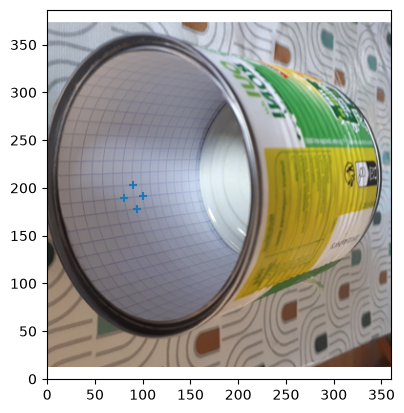

In [21]:
P1 = np.array([80, 189])
P2 = np.array([90, 203])
P3 = np.array([100, 192])
P4 = np.array([94, 178])
poro_pts = np.array([P1, P2, P3, P4])
plt.scatter(poro_pts[:, 0], poro_pts[:, 1], marker='+')
plt.imshow(img, origin='lower')
plt.show()

## 2-Projection des points de porosité sur le cylindre (calcul)

In [22]:
def projeter_sur_cyl(P, O=O):
    '''Projette un point P sur le plan x = -RADIUS par rapport au point d'observation O
    args :
        P (np.array(3)) : les coordonnées du point observé
        O (np.array(3)) : les coordonnées du point d'observation
    return :
        I (np.array(3)) : les coordonnées de la projection du point P sur le plan de projection par homothétie de centre O (le point d'observation)
        '''
    # Vecteur OP
    OP = O - P
    # 2 vecteurs normal à OP v1 et v2
    v1 = np.array([-OP[1], OP[0], 0])
    v2 = np.array([-OP[2], 0, OP[0]])
    # Calcul des deux biais d1 et d2
    d1 = v1 @ O
    d2 = v2 @ O
    # 1 vecteur normal au plan x = -RADIUS
    v3 = np.array([1, 0, 0])
    # Calcul du biais d3
    d3 = v3 @ np.array([-RADIUS, 0, 0])
    # Calcul de l'intersection de OP avec le plan
    I = np.linalg.solve(np.array([v1, v2, v3]), np.array([d1, d2, d3])) ###correction
    return I


In [23]:
# 1 - scaler
pts_1 = scaler.transform(np.array([P1, P2, P3, P4]))
# 2 - pca
pts_2 = pca.transform(pts_1)
# 3 - pcap inverse
pts_3 = pca_p.inverse_transform(np.column_stack((pts_2[:, 0], pts_2[:, 1]))) # inversion de l'axe Y
# 4 - scaler_p inverse
pts_4 = scaler_p.inverse_transform(pts_3)
# 5 - ajout de la dimension manquante
# P0 appartient au plan de projection et n est le vecteur normal au plan de projection
O = best_O
n = O
P0 = 0.8 * O
# On cherche le z sachant x et y, on a donc : z = P0_z - (n_x*(x - P0_x) + n_y*(y - P0_y)) / n_z
Z_pts_5 = list(map(lambda Xp, Yp: P0[2] - (n[0]*(Xp - P0[0]) + n[1]*(Yp - P0[1])) / n[2], pts_4[:, 0], pts_4[:, 1]))
pts_5 = np.column_stack((pts_4, Z_pts_5))
# 6 - projection sur le plan x = -RADIUS
pts_6 = list(map(lambda P: projeter_sur_cyl(P, O), pts_5))
pts_6 = np.array(pts_6)


## 3-Visualisation des points de porosité sur le plan de projection et sur le cylindre

Text(0.5, 1.0, 'Projection sur le plan x = -RADIUS')

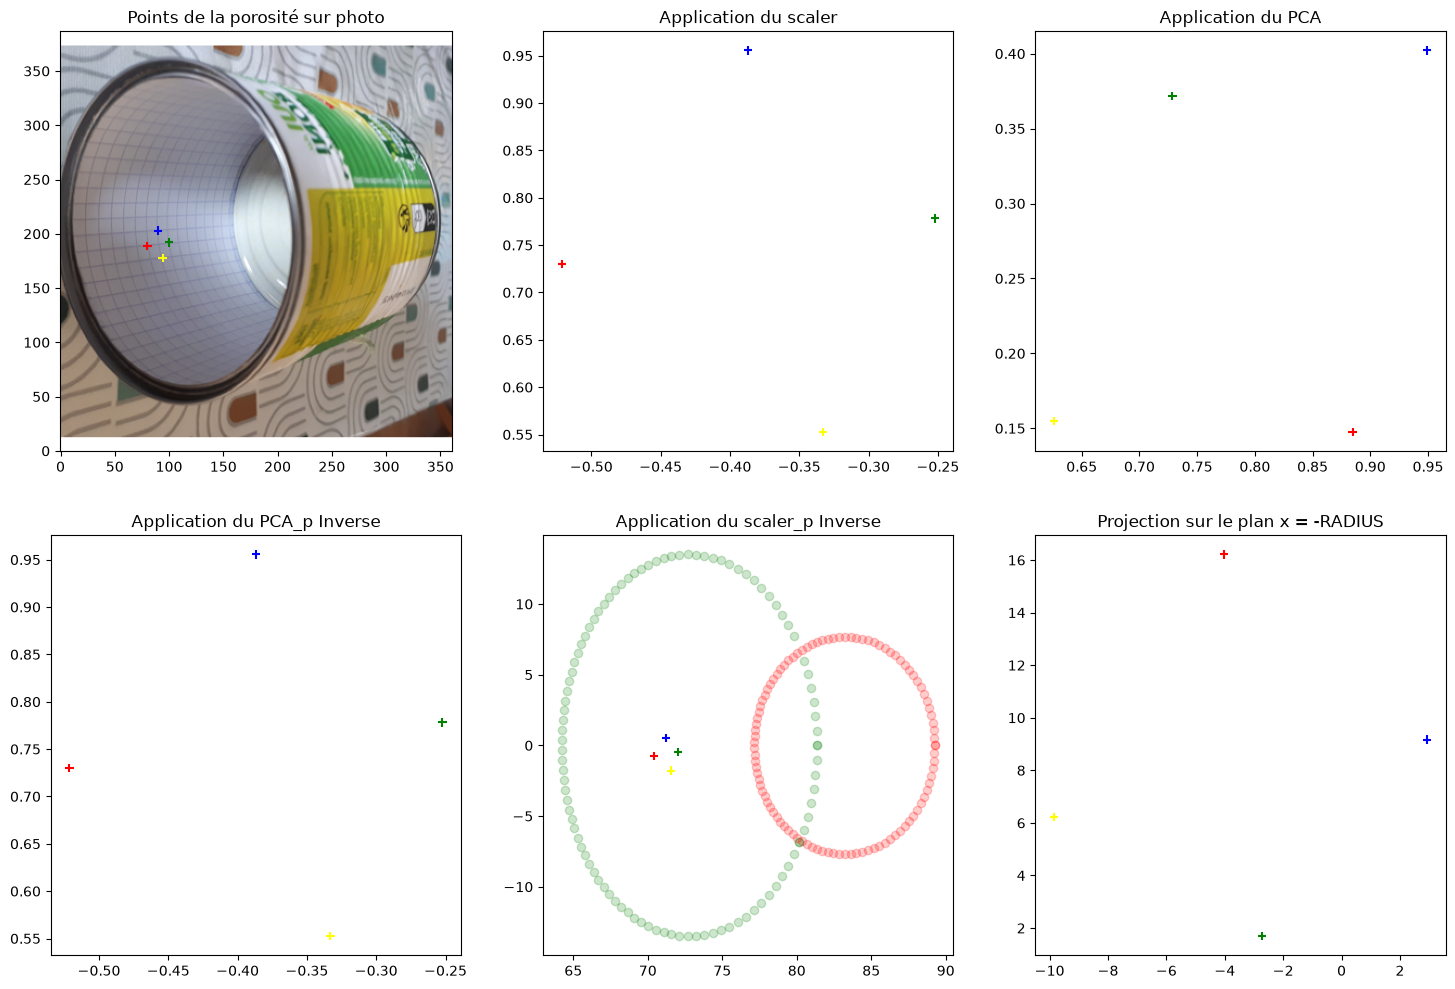

In [24]:
fig, ax = plt.subplots(2, 3, figsize=(18, 12))
ax = ax.flatten()
ax[0].scatter(poro_pts[:, 0], poro_pts[:, 1], marker='+', c=['red', 'blue', 'green', 'yellow'])
ax[0].imshow(img, origin='lower')
ax[0].set_title('Points de la porosité sur photo')
ax[1].scatter(pts_1[:, 0], pts_1[:, 1], marker='+', c=['red', 'blue', 'green', 'yellow'])
ax[1].set_title('Application du scaler')
ax[2].scatter(pts_2[:, 0], pts_2[:, 1], marker='+', c=['red', 'blue', 'green', 'yellow'])
ax[2].set_title('Application du PCA')
ax[3].scatter(pts_3[:, 0], pts_3[:, 1], marker='+', c=['red', 'blue', 'green', 'yellow']) # Attention à l'inversion aléatoire de l'axe Y avec pca (changer dans Partie-1 - 14 le cas échéant
ax[3].set_title('Application du PCA_p Inverse')
ax[4].scatter(pts_4[:, 0], pts_4[:, 1], marker='+', c=['red', 'blue', 'green', 'yellow'])
ax[4].scatter(cyl_proj1[:, 0], cyl_proj1[:, 1], c='green', alpha=0.2)
ax[4].scatter(cyl_proj2[:, 0], cyl_proj2[:, 1], c='red', alpha=0.2)
ax[4].set_title('Application du scaler_p Inverse')
ax[5].scatter(pts_6[:, 1], pts_6[:, 2], marker='+', c=['red', 'blue', 'green', 'yellow'])
ax[5].set_title('Projection sur le plan x = -RADIUS')

Text(0.5, 0.92, 'Projection du cylindre sur le plan de projection')

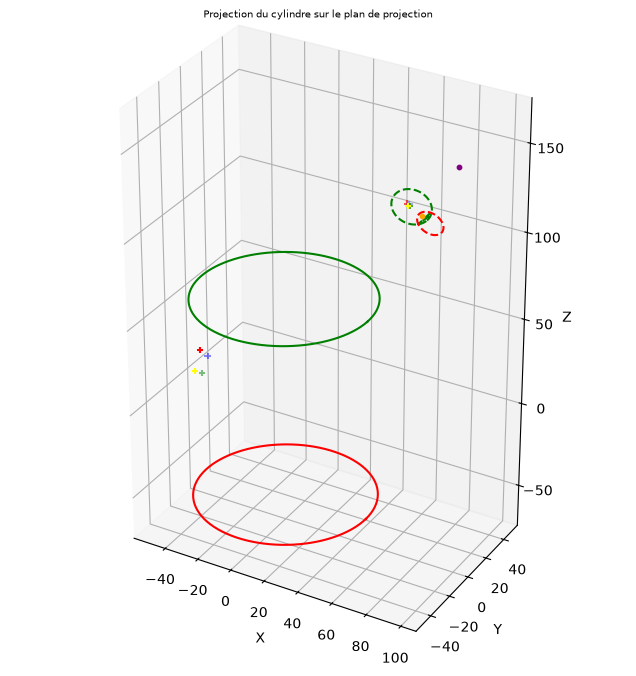

In [25]:
# Visualisation 3D
# Définition de la figure et des axes 3D
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Tracé des cercles de base du cylindre
ax.plot(x_circle1, y_circle1, z_circle1, color='green', label='Cercle1 de base du cylindre')
ax.plot(x_circle2, y_circle2, z_circle2, color='red', label='Cercle2 de base du cylindre')

# Tracé du point P0
ax.scatter(P0[0], P0[1], P0[2], color='orange', s=10, label='Point P0 (centre du plan de projection)')

# Tracé du point d'observation' O
ax.scatter(O[0], O[1], O[2], color='purple', s=10, label='Point d\'observation O')

# Tracé de la projection du cylindre sur le plan de projection
ax.plot(cyl_proj1[:, 0], cyl_proj1[:, 1], cyl_proj1[:, 2], color='green', linestyle='--', label='Projection du cercle1 sur le plan')
ax.plot(cyl_proj2[:, 0], cyl_proj2[:, 1], cyl_proj2[:, 2], color='red', linestyle='--', label='Projection du cercle2 sur le plan')

# Tracé de la projection de la porosité sur le plan de projection
ax.scatter(pts_5[:, 0], pts_5[:, 1], pts_5[:, 2], marker='+', c=['red', 'blue', 'green', 'yellow'], label='Projection de la porosité sur le plan')
# Tracé des points caractéristiques de la porosité sur le cylindre
ax.scatter(pts_6[:, 0], pts_6[:, 1], pts_6[:, 2], marker='+', c=['red', 'blue', 'green', 'yellow'])

# Configuration du graphique
ax.set_aspect('equal')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Projection du cylindre sur le plan de projection', fontsize=7)


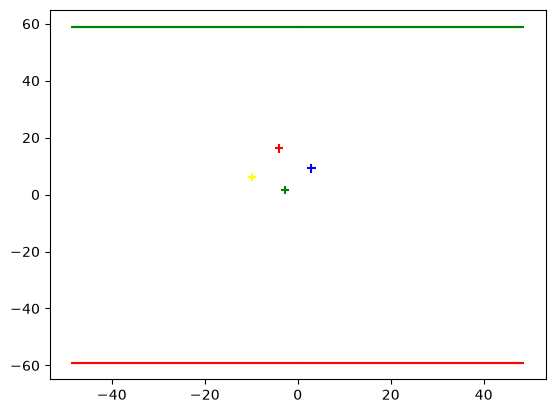

In [26]:

# Tracé des cercles de base du cylindre
plt.plot(y_circle1, z_circle1, color='green', label='Cercle1 de base du cylindre')
plt.plot(y_circle2, z_circle2, color='red', label='Cercle2 de base du cylindre')

# Tracé des points caractéristiques de la porosité
plt.scatter(pts_6[:, 1], pts_6[:, 2], marker='+', c=['red', 'blue', 'green', 'yellow'])


## 4-Calcul de la largeur et de la longueur réelle de la porosité

In [27]:
print('coordonnées des points de la porosité :')
print('Point 1 : ', pts_6[0])
print('Point 2 : ', pts_6[1])
print('Point 3 : ', pts_6[2])
print('Point 4 : ', pts_6[3])
print('Longueur réelle de la porosité : ', dist(pts_6[0], pts_6[2]))
print('Largeur réelle de la porosité : ', dist(pts_6[1], pts_6[3]))

coordonnées des points de la porosité :
Point 1 :  [-48.5         -4.03672007  16.21135984]
Point 2 :  [-48.5          2.92931868   9.16864654]
Point 3 :  [-48.5         -2.72208015   1.68707749]
Point 4 :  [-48.5         -9.84685144   6.23093657]
Longueur réelle de la porosité :  14.583657148157142
Largeur réelle de la porosité :  13.10956379299612
